<a href="https://colab.research.google.com/github/ashsiendo/DATA-201-Labs/blob/main/Lab08_week8_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Regularization Hitters**

## Regularization and Model Complexity: Ridge vs. Lasso


### Learning goals
By the end of this lab, you will be able to:
1. Fit a linear regression baseline and identify overfitting using training and test error.
2. Explain how ridge (L2) and lasso (L1) change the fitted coefficients.
3. Select regularization strength (`alpha`) using **5-fold cross-validation on the training set**.
4. Compare model performance fairly on an untouched test set.
5. Explain the tradeoff among bias, variance, prediction accuracy, and interpretability.

**Important connection:** We used regularization with logistic regression in Week 7. Today, we use **linear regression** because salary is a continuous outcome, not a class. Classification metrics such as accuracy and ROC-AUC are **not** appropriate here; we use MSE, RMSE, and R².

### Part 1 — Load the ISLP Hitters dataset

**Dataset background:** The data contain professional baseball players' 1986 statistics and their 1987 salaries. `Salary` is reported in **thousands of dollars**. The original dataset has 322 rows; some salary values are missing. This is the dataset used in ISLP's Chapter 6 regularization lab.

**Colab:** Run the next cell to install ISLP. You need to run it each time in Colab.


NOTE TO SELF: salary is quantitative variable, so linear reg is used here

In [1]:
%pip -q install ISLP # -q means quiet; reduces installation output

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



In [3]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values(ascending=False)) # count missing values per column, sorted from most to least

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
Salary       59
AtBat         0
HmRun         0
Hits          0
Runs          0
RBI           0
Years         0
Walks         0
CHits         0
CHmRun        0
CRuns         0
CAtBat        0
CRBI          0
CWalks        0
Division      0
League        0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
dtype: int64


***Note to self:*** `Salary` is the target and not the predictor. Rows are being removed since we don't know their actual outcomes, needed to train and evaluate a supervised model

In [4]:
hitters['Salary'].max()*1000 # highest salary
#hitters['Salary'].min()*1000

2460000.0

In [5]:
hitters['Salary'].min()*1000

67500.0

**Discuss:** Which variable is the outcome? Which columns are categorical? Why must we exclude players with missing Salary values when training and evaluating our model?

We remove rows with missing salary. For other predictors, this dataset does not require additional missing-value handling after this step. We will encode categorical variables using a pipeline so their transformations are learned correctly in cross-validation.

Since the (NA) are in Salary column only, dropna(subset=['Salary']) removes rows where Salary is missing. Then .copy() creates a separate DataFrame containing the remaining rows. and [hitters = ] assigns that new DataFrame to the variable hitters.

In [6]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy() # drop rows with missing salary values
# .copy() creates a separate DataFrame to work with

#Set your features and target
X = hitters.drop(columns='Salary') # exclude salary from features to avoid showing model its target
y = hitters['Salary']    # salary in thousands of dollars

# define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist() # numerical features will be scaled because they have different units/ranges
category_cols = X.select_dtypes(exclude=np.number).columns.tolist() # categorical features will be one-hot encoded
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
) #training 75, test 25; random_state makes split reproducible

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


### Part 2 - Prepare the data and build a baseline

Why scale? Regularization penalizes **coefficients**. Salary predictors such as career at-bats and years played have different units, so comparing coefficient magnitudes is unfair unless numerical inputs are standardized.

We use the **same preprocessing** for all three models. The pipeline protects the training folds during cross-validation: the scaler fits only on each fold's training portion.

In [7]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols), # scale numerical columns (different units/ranges)
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols) # convert categorical columns into numeric indicators
            ])

# Note:
  # ColumnTransformer applies different preprocessing to selected columns
  # handle_unknown='ignore': avoids errors if test data has a category not seen during training
  # drop='first' drops one category as a reference to avoid redundant columns

baseline = Pipeline([ # preprocess first, then run linear regression
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
]) #baseline (no regularization) to compare with Ridge and Lasso

baseline.fit(X_train, y_train) # fit preprocessing and regression model using training data

def measure(name, fitted_model):  # eval function ("rubric") for comparing models
    train_pred = fitted_model.predict(X_train) # predict using training observations
    test_pred = fitted_model.predict(X_test) # predict using unseen test observations
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)), # training prediction error
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)), # test prediction error (generalization)
        'Test R²': r2_score(y_test, test_pred) # how well model explains variation in Salary on test data
    }
# Note: RMSE is lower = better; R² is higher = generally better
#   No confusion matrix because Salary is numerical (regression, not classification)
#   fitted_model can be the baseline, Ridge, or Lasso; this function works for all three

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2)) # 2 decimal places

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


Training R²: Measures how much variation in Y is explained by the model on the data used to fit it.

Here we are find the Test R² which measures how well the model predicts variation in Y for new observations that were not used during training.

RMSE is measured in **thousands of dollars**, like `Salary`. Lower RMSE is better; higher R² is better.

A large gap between training RMSE and test RMSE can indicate overfitting, but a small gap alone does not prove generalization.

**Question 1:** What is the baseline test RMSE? Explain why the pattern (the training RMSE smaller than the test RMSE) is common.

> The baseline test RMSE is 357.05 (about $357,050), and the training RMSE is 289.33. The training RMSE is lower because the model has already seen that data and can predict it more accurately. The test data, however, is new to the model, and prediction errors are often higher, so the difference is normal and does not always mean the model is overfitting.

### Part 3 - The regularization dial: ridge vs. lasso

Ordinary linear regression finds the coefficients that minimize Residual Sum of Squares(RSS) on the training data.

Ridge and lasso also try to minimize RSS, but they add a penalty for large coefficients.

- **Ridge (L2):** training RSS + α × sum of squared coefficients. It generally keeps all predictors but shrinks their weights.
- **Lasso (L1):** training RSS + α × sum of absolute coefficients. It can shrink some weights exactly to zero.

**In ISLP, the penalty strength is called λ (lambda); scikit-learn uses `alpha` for `Ridge` and `Lasso`.** A larger α means stronger regularization. The intercept is not penalized.

**Important:** The exact numerical relationship depends on how the software defines and scales the loss function. Also, an alpha of 1 in ridge is not directly equivalent in effect to an alpha of 1 in lasso.

In Part 3, we will the same training set and change α and observe what happens to the coefficients. The goal is to understand regularization. In Part 4, we will use cross-validation to find the best α.

Note: We calculated the sum of the absolute coefficients for both Ridge and Lasso to measure how much the coefficients shrink as alpha increases. This is only a summary measure. Ridge still uses an L2 penalty, while Lasso uses an L1 penalty during training.

***Additional note to self:*** The outer loop selects either Ridge or Lasso, and the inner loop then tries six different alpha values for each. For each combination, it constructs and fits a pipeline to the training data. The higher the alpha value, the stronger the regularization. Lasso uses iterative optimization, so `max_iter` is the max number of iterations it will run for.

In [8]:
alpha_examples = [0.01, 0.1, 1, 10, 100, 1000] # larger alpha = stronger penalty and more coefficient shrinkage
rows = [] # empty list to store model results later

# loop through both Ridge and Lasso
for kind, estimator in [('Ridge', Ridge()), ('Lasso', Lasso(max_iter=30000))]: # kind = model name; estimator = actual Ridge or Lasso model
                                                                               # Ridge can often calc coefficients directly; Lasso uses iterative optimization
                                                                               # max_iter=30000 sets max number of iterations Lasso can attempt

    for a in alpha_examples: # try each of 6 alpha values for both models (12 fits total)
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a)) # set current model's alpha
        ])
        pipe.fit(X_train, y_train) # preprocess and fit the model using training data

        # get fitted model's coefficients from inside the pipeline
        # 'model' is pipeline step name; coef_ contains its learned feature weights (not the intercept)
        coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
            'Model': kind, 'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients (approximately)
            'Coefficient L1 size': float(np.sum(np.abs(coefs))), # sum absolute coefficient sizes; for comparing shrinkage, not Ridge's penalty
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))) # evaluate error on same training rows used to fit
        })

# convert list of result dictionaries into a DataFrame for comparing all 12 model/alpha combinations
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2)) # show two decimal places; stored values not rounded

# Note to self:
  # stronger alpha = stronger regularization, generally smaller coefficients and higher training error
  # a higher training error is not automatically worse; validation/CV will tell us whether the simpler model generalizes
  # Ridge shrinks coefficients but usually keeps them; Lasso can set coefficients exactly to zero
  # Lasso with zero predictor coefficients can still predict constant using its intercept (not a useful detailed model)
  # five coefficients might be easier to explain than nine, but choose based on validation results and the goal, not the count alone

,Model,alpha,Nonzero coefficients,Coefficient L1 size,Training RMSE
0,Ridge,0.01,19,2855.93,289.33
1,Ridge,0.10,19,2608.64,289.38
2,Ridge,1.00,19,1893.70,290.72
3,Ridge,10.00,19,854.92,298.20
4,Ridge,100.00,19,500.83,309.50
5,Ridge,1000.00,19,265.70,344.14
6,Lasso,0.01,19,2861.11,289.33
7,Lasso,0.10,19,2589.13,289.38
8,Lasso,1.00,18,1731.28,290.91
9,Lasso,10.00,9,524.31,303.10


- Ridge: The coefficients generally shrink as alpha increases, but predictors remain in the model.
- Lasso: Some coefficients become zero as alpha increases, effectively removing predictors.
- Training RMSE: Stronger regularization generally increases training error because the model has less freedom to fit the data.

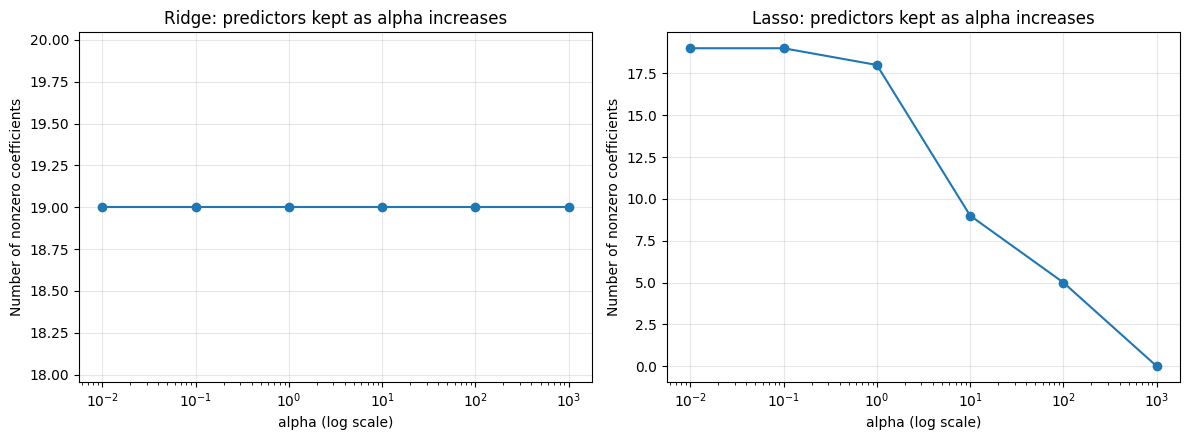

In [9]:
# compare how many coefficients each model keeps as alpha increases
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5)) # one plot for Ridge, one for Lasso
for ax, kind in zip(axes, ['Ridge', 'Lasso']): # pair each subplot with its model name
    subset = alpha_table[alpha_table['Model'] == kind] # use only rows for current model
    ax.semilogx(subset['alpha'], subset['Nonzero coefficients'], marker='o') # log scale for alpha
    ax.set_title(f'{kind}: predictors kept as alpha increases')
    ax.set_xlabel('alpha (log scale)')
    ax.set_ylabel('Number of nonzero coefficients')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

> ***Note to self:*** This graph shows HOW MANY coefficients remain, but not how large the coefficients are or how well the models predict- Ridge's count stays flat while Lasso's drops at stronger α.



**Question 2:** How does the number of nonzero coefficients change for ridge and lasso? What happens to training RMSE as α increases? Why does a higher training error **not necessarily** mean a worse model?
> All 19 coefficients stayed non-zero for every α we tried, but their values got smaller. For Lasso, we saw 19 non-zero coefficients at α=0.01 and α=0.1, 18 at α=1, 9 at α=10, 5 at α=100, and none at α=1000. As α went up in both methods, the training RMSE also went up, which makes sense because stronger regularization makes it harder for the model to fit the training data so closely. A higher training error doesn't necessarily mean the model is any worse, though. A simpler model may in fact be less prone to overfitting and could end up performing better on new data. We'll look at that in Part 4 using cv.

### Part 4 - Choose α using cross-validation
We must not choose α because it gives the best **test** result. The test set is being saved for the final evaluation.

We'll use the Week 6–7 workflow: **Pipeline → GridSearchCV → 5-fold CV on training data → choose α → refit on all training data → test once**.

For ridge, try more α values spanning weak to strong penalties. Lasso also uses a logarithmic grid. Both models are assessed with the **same folds and metric**. The scoring is negative MSE because scikit-learn selects the highest score.

Why negative mean squared error?
Ordinarily, lower MSE is better. However, scikit-learn's GridSearchCV is designed to select the model with the highest score. Therefore, it uses negative MSE.

In [10]:
# define same five folds for evaluating both models (within TRAINING data)

cv5 = KFold(n_splits=5, shuffle=True, random_state=42) # setting up CV, kfold splitting dataset into 5 parts
# shuffle - shuffle rows before dividing them into folds (rather than using their original order)
# random state - repeat the same shuffle/splits when rerunning

ridge_grid = GridSearchCV(
    Pipeline([('preprocess', make_preprocessor()), ('model', Ridge())]),
    {'model__alpha': np.logspace(-2, 5, 40)},
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1 #Uses all available CPU cores to speed up the computations
)
lasso_grid = GridSearchCV(
    Pipeline([('preprocess', make_preprocessor()),
              ('model', Lasso(max_iter=30000))]),
    {'model__alpha': np.logspace(-2, 4, 40)},
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1
)

# GridSearchCV tests alpha values using 5-fold CV
# model__alpha = alpha parameter inside the "model" pipeline step
    # best_params_ retrieves best alpha from CV
    # model__alpha a pipeline parameter, not local/global scope

ridge_grid.fit(X_train, y_train)
lasso_grid.fit(X_train, y_train)

print('Best ridge alpha:', ridge_grid.best_params_['model__alpha'])
print('Best ridge CV RMSE:', np.sqrt(-ridge_grid.best_score_))
print('Best lasso alpha:', lasso_grid.best_params_['model__alpha'])
print('Best lasso CV RMSE:', np.sqrt(-lasso_grid.best_score_))

Best ridge alpha: 203.09176209047348
Best ridge CV RMSE: 340.7959841903925
Best lasso alpha: 24.244620170823307
Best lasso CV RMSE: 349.49427101392234


40 alpha x 5 folds = 200 across Ridge and Lasso, that is 400 cross-validation fits, plus one final refit for each model using all of X_train and y_train.

n_jobs=-1 tells GridSearchCV to use all available CPU cores to run multiple model fits at the same time, potentially speeding up cross-validation.

In Google Colab, these computations run on Colab's remote CPU, not your personal computer. When GridSearchCV finishes running, it stops using the CPU cores for that task, making them available for other computations.

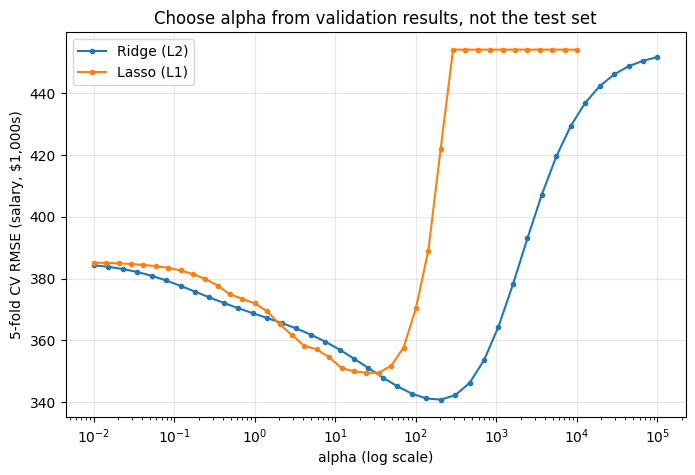

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, grid in [('Ridge (L2)', ridge_grid), ('Lasso (L1)', lasso_grid)]:
    a = grid.cv_results_['param_model__alpha'].astype(float)
    rmse = np.sqrt(-grid.cv_results_['mean_test_score'])
    ax.semilogx(a, rmse, marker='.', label=label)
ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('5-fold CV RMSE (salary, $1,000s)')
ax.set_title('Choose alpha from validation results, not the test set')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# CV RMSE vs alpha for both models
# lower RMSE = better; too much penalty can lead to underfitting

**Question 3:** For each model, identify the best α and CV RMSE. What happens when α becomes **too large**? Explain using the word **bias**.


As α increases, regularization becomes stronger, pushing the coefficients toward zero. When α becomes too large, the model becomes overly restricted and cannot capture important relationships between the predictors and salary.

This leads to:
- Higher bias: The model is too simple to capture the underlying relationships.
- Lower variance: Predictions become less sensitive to changes in the training data.
- Underfitting: Both training and validation errors tend to increase.

The main takeaway: Regularization introduces some bias to reduce variance and potentially improve prediction accuracy. However, too much regularization creates excessive bias and increases prediction error.


> **Ridge:** α = 203.09, CV RMSE = 340.80

> **Lasso:** α = 24.24, CV RMSE = 349.49

### Part 5 - Final comparison on the untouched test set
`GridSearchCV` automatically refits its best pipeline on **all training rows** (`refit=True`, the default). Now we are ready to compare all three models on the same test set.

In [12]:
#adding to "results" from previous cell
results += [
    measure('Ridge (L2, tuned)', ridge_grid.best_estimator_), # model label used in comparison table
    measure('Lasso (L1, tuned)', lasso_grid.best_estimator_)
]
# it's tuned bc of the grid search cv
# note: += adds to the existing list; rerunning this cell can duplicate rows

#Create a comparison table
comparison = pd.DataFrame(results).sort_values('Test RMSE')
display(comparison.round(2))

#retrieve the test RMSE of our original linear regression model.
base_rmse = results[0]['Test RMSE']

#add column to comparison (percentage reduction or increase in test RMSE compared with ordinary linear regression.)
comparison['Change vs. baseline (%)'] = 100 * (base_rmse - comparison['Test RMSE']) / base_rmse

display(comparison[['Model', 'Test RMSE', 'Change vs. baseline (%)']].round(2))
# note: positive % = lower RMSE (better); negative % = higher RMSE (worse)

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41
2,"Lasso (L1, tuned)",308.33,385.62,0.31
1,"Ridge (L2, tuned)",314.93,390.26,0.30


,Model,Test RMSE,Change vs. baseline (%)
0,Linear regression (no penalty),357.05,0.0
2,"Lasso (L1, tuned)",385.62,-8.0
1,"Ridge (L2, tuned)",390.26,-9.3


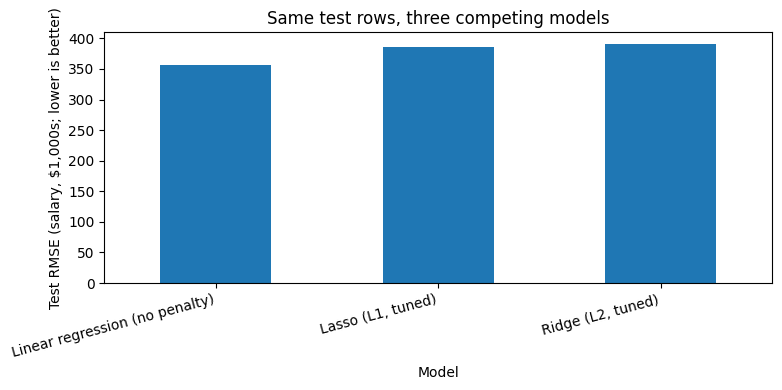

In [13]:
# compare test RMSE across the three models
# lower RMSE = better predictions on test set

ax = comparison.plot(kind='bar', x='Model', y='Test RMSE', legend=False, figsize=(8, 4))
ax.set_ylabel('Test RMSE (salary, $1,000s; lower is better)')
ax.set_title('Same test rows, three competing models')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

**Question 4:** Which model has the lowest test RMSE? How much better or worse is it than ordinary least squares (in %)? Are the differences large enough that you would confidently call one model superior? A single test split is useful, but it is not proof that a small performance gap will persist.

**Important:** Regularization is an attempt to reduce variance by allowing some bias. Whether this improves test RMSE depends on the dataset.
> Linear regression (OLS) had the lowest test RMSE at 357.05. Lasso at 385.62, and Ridge at 390.26. Lasso was around 8.0% worse than OLS; Ridge around 9.3%. OLS did best in this test, but I wouldn't be comfortable saying it's the best model overall just on the basis of one test split, so we'd need more testing to be confident that the results are valid.

### Part 6 - Interpretability: what did the model retain?
The coefficient table below shows how the same predictors behave under ordinary least squares, tuned ridge, and tuned lasso. The numeric predictors have been standardized; categorical predictors have been encoded. This makes the three models comparable **for the same transformed feature**, though comparisons of coefficient importance across all features still require caution.

In [14]:
# get feature names after preprocessing
# compare coefficients from OLS, Ridge, and Lasso

feature_names = baseline.named_steps['preprocess'].get_feature_names_out()
coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': baseline.named_steps['model'].coef_,
    'Ridge': ridge_grid.best_estimator_.named_steps['model'].coef_,
    'Lasso': lasso_grid.best_estimator_.named_steps['model'].coef_
})
coef_table['Lasso is zero'] = np.isclose(coef_table['Lasso'], 0, atol=1e-6) # check which lasso coefficients are approximately zero
coef_table = coef_table.sort_values('Lasso', key=lambda s: s.abs(), ascending=False) # sort by largest absolute lasso coefficient
display(coef_table.round(2))
print('Number of retained lasso coefficients:', int((~coef_table['Lasso is zero']).sum()))
print('Number dropped by lasso:', int(coef_table['Lasso is zero'].sum()))

,Feature,OLS,Ridge,Lasso,Lasso is zero
10,num__CRuns,602.97,34.03,123.59,False
1,num__Hits,379.23,40.52,104.58,False
11,num__CRBI,238.25,30.18,69.52,False
13,num__PutOuts,80.70,45.41,66.17,False
5,num__Walks,113.43,31.26,41.63,False
17,cat__Division_W,-100.03,-23.55,-19.70,False
0,num__AtBat,-252.65,21.73,0.00,True
2,num__HmRun,64.67,12.01,0.00,True
6,num__Years,35.91,18.01,0.00,True
4,num__RBI,-52.67,20.89,0.00,True


Number of retained lasso coefficients: 6
Number dropped by lasso: 13


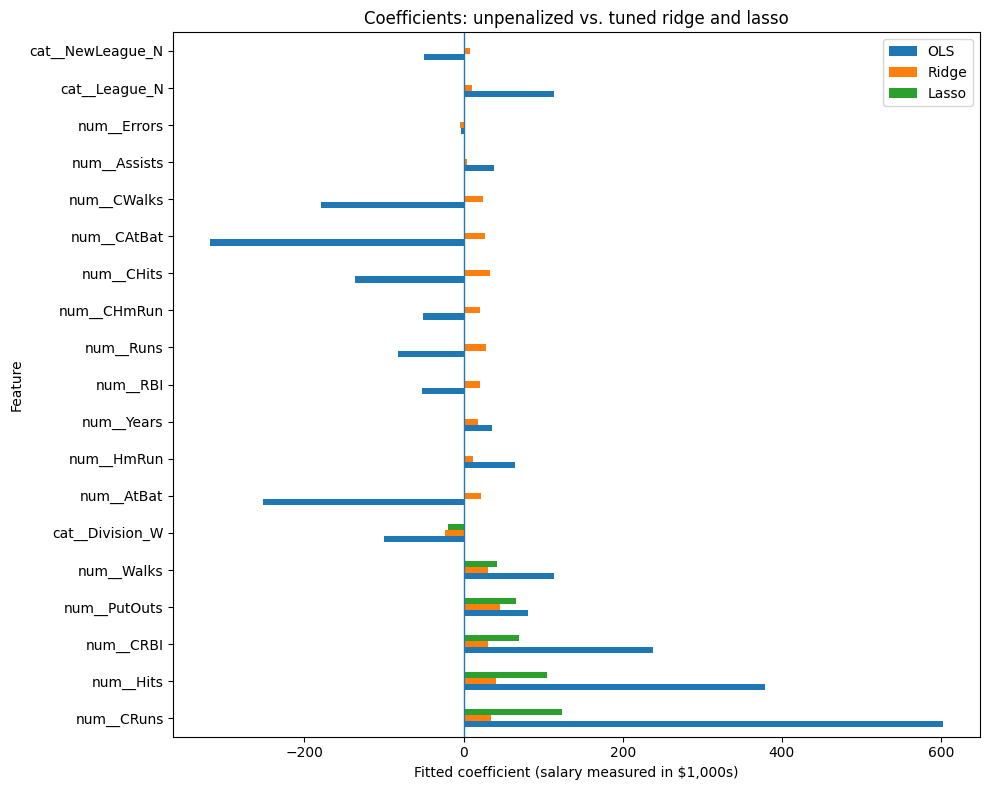

In [15]:
plot_df = coef_table.set_index('Feature')[['OLS', 'Ridge', 'Lasso']]
plot_df.plot(kind='barh', figsize=(10, 8))
plt.axvline(0, linewidth=1) # reference line @ coefficient = 0
plt.xlabel('Fitted coefficient (salary measured in $1,000s)')
plt.title('Coefficients: unpenalized vs. tuned ridge and lasso')
plt.tight_layout()
plt.show()

# Ridge shrinks coefficients; Lasso sets some to zero
# Lasso is simpler, but not necessarily more accurate
# note: domain knowledge helps interpret which predictors matter

**Question 5:** Name two variables retained by lasso and two dropped (if available). Does a zero coefficient prove a variable has no relationship with salary? Explain why **correlated predictors** make that interpretation especially risky.
>Lasso kept `CRuns` and `Hits` but dropped `AtBat` and `Runs`. A zero coefficient does not always mean those variables are unimportant; for example, at-bats might be linked to years of experience-the more years you play, the more at-bats you get, and runs and hits might also be connected to at-bats. The variables can be highly correlated, so Lasso may keep some and drop others, but that doesn't mean the ones it dropped are unimportant.

>***Note to self:*** Feature selection is not the same as proving which variables matter in the real world

**Interpretability vs. flexibility:** Lasso may provide a shorter description of salary by using fewer features. Ridge typically keeps more predictors and may distribute weight among correlated statistics. Neither method changes a linear regression into a nonlinear one by itself; regularization constrains coefficients and therefore affects **effective complexity**.

**Bias–variance connection:** Weak regularization allows coefficients to respond strongly to a particular sample (potentially high variance). Very strong regularization suppresses important relationships (higher bias). CV tries to choose a reasonable balance.

### Optional extension — When regularization becomes more valuable
In Part 5 you may observe only small improvements. That is informative: with roughly 263 usable players and fewer than 20 original predictors, ordinary least squares may already work reasonably well.

To create a **more flexible** model, add pairwise interaction terms between the numerical variables. This uses an idea from Week 6: more features let the model fit more complicated relationships, but make it easier to overfit. Here is an optional demonstration using a larger predictor set.

**Note:** Because we use the same test set again to illustrate a new model family, treat this as a classroom illustration, **not** as an unbiased final claim about generalization. In a serious study, choose the model family before opening the held-out test set.

In [16]:
# OPTIONAL: Interactions among numeric predictors, plus encoded categories.
# PolynomialFeatures(interaction_only=True) creates x1*x2, but not x1**2.
def make_expanded_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([
            ('scale', StandardScaler()),
            ('interact', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
            ('rescale', StandardScaler())
        ]), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
    ])

# compare OLS, Ridge, and Lasso after adding interaction terms
expanded_ols = Pipeline([
    ('preprocess', make_expanded_preprocessor()),
    ('model', LinearRegression())
])
expanded_ols.fit(X_train, y_train)

expanded_ridge = GridSearchCV(
    Pipeline([('preprocess', make_expanded_preprocessor()), ('model', Ridge())]),
    {'model__alpha': np.logspace(0, 5, 15)},
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1
)
expanded_lasso = GridSearchCV(
    Pipeline([('preprocess', make_expanded_preprocessor()),
              ('model', Lasso(max_iter=30000))]),
    {'model__alpha': np.logspace(-1, 3, 15)},
    scoring='neg_mean_squared_error', cv=cv5, n_jobs=-1
)
expanded_ridge.fit(X_train, y_train)
expanded_lasso.fit(X_train, y_train)

# compare training and test errors for the expanded models
expanded_results = pd.DataFrame([
    measure('OLS with interactions', expanded_ols),
    measure('Ridge with interactions', expanded_ridge.best_estimator_),
    measure('Lasso with interactions', expanded_lasso.best_estimator_)
])
print('Expanded feature count:', len(expanded_ols.named_steps['preprocess'].get_feature_names_out()))
display(expanded_results.round(2))

Expanded feature count: 139


,Model,Train RMSE,Test RMSE,Test R²
0,OLS with interactions,77.56,492.17,-0.12
1,Ridge with interactions,157.53,336.66,0.48
2,Lasso with interactions,157.44,330.89,0.49


**Optional question:** Did adding interactions lower the training error but increase the test error for ordinary least squares? Did ridge or lasso improve the expanded model? Connect your answer to the **bias–variance tradeoff** and the Week 8 slide about many features relative to sample size.

> After adding the interaction terms, the OLS training RMSE dropped from 289.33 to 77.56- test RMSE went from 357.05 to 492.17. The added features made the model more flexible, so it likely started to fit the noise in the training data, leading to overfitting and higher variance.
> Ridge and Lasso both improved the test performance of the expanded model- RMSEs of 336.66 and 330.89, respectively. Regularization adds some bias, but reduces variance by constraining the model's complexity, useful when you have a lot of predictors relative to the number of samples.


---
### Exit ticket: answer in 3–5 sentences
A student says: *“Lasso removed five predictors from model, so those predictors do not affect salary. Also, ridge has a higher training error than linear regression, so ridge is clearly worse.”*

What is wrong with both claims? Use **training vs. test performance**, **bias–variance**, and **interpretability** in your explanation.

>For both claims, it doesn't always mean the predictors have nothing to do with salary when Lasso removes them, but rather, they might be correlated and share similar information. If Ridge shows a higher training error than linear regression, it isn't necessarily performing worse; however, fitting the training data too closely can lead to overfitting. Regularization adds some bias, reducing variance and potentially improving how the model works on new data, so focusing on test performance and how easy the model is to interpret is considered to be better than solely looking at training error or how many predictors remain.
